# 8. STEP 7 – Cross Validation 및 Hyperparameter Tuning
## STEP 4 이상치 심화전처리·STEP 6 불균형 실측 연계 · 실행완료

**목적:** 한 번의 분할에 따른 변동을 확인하고, 같은 학습 자료·평가 규칙에서 모델 설정을 체계적으로 비교합니다.

**입력:** 원시 27개 특성, 원래 Train 1,358건·Valid 291건·별도 Test 292건. 원본의 이상치 후보를 임의 제거하거나 새 특성을 추가하지 않습니다.

**주 검증:** 유사 후보 그룹을 분리한 StratifiedGroupKFold 5-Fold. 요청하신 일반 StratifiedKFold 5-Fold도 함께 실행합니다. **Test는 CV·튜닝·선정·성능 평가 모두에서 제외**합니다.

**탐색:** 실제 GridSearchCV, 4개 모델 계열·124개 조건, 620회 Grid CV 적합. 기존 모델·튜닝 모델 비교 및 재현 확인을 포함한 완주 재현 설계 713회. 캐시 재실행은 계산 결과를 재사용합니다.

## 실행 방법

1. 전체 ZIP을 해제하고 `steel_fault_step7` 폴더를 VS Code에서 엽니다.
2. 검증 환경은 Python 3.12입니다. 선택한 커널의 터미널에서 `python -m pip install -r requirements.txt`를 실행합니다.
3. 커널을 다시 시작하고 위에서부터 실행합니다. 코드·원자료·캐시가 필요하므로 이 노트북만 따로 옮기지 마세요.
4. `python run_step7.py`로도 전체 실행과 보고서 생성을 재현할 수 있습니다.

Windows의 기본 CP949 읽기를 피하도록 모든 텍스트 읽기에 UTF-8을 명시했습니다. 실제 Windows OS 실행 검증과 CP949 모의 검증은 구분합니다.

In [1]:
from pathlib import Path
import sys,json,platform,inspect
import numpy as np
import pandas as pd
import joblib
from IPython.display import display,Image,HTML,Code
candidates=[Path.cwd(),Path.cwd()/'steel_fault_step7',Path.cwd().parent/'steel_fault_step7']
ROOT=next((p.resolve() for p in candidates if (p/'step7_experiments.py').is_file()),None)
if ROOT is None:raise FileNotFoundError('전체 ZIP의 steel_fault_step7 폴더에서 실행하세요.')
sys.path.insert(0,str(ROOT))
import step7_experiments as e
import step7_models as m
from step7_report import build_report,cv_display,valid_display,interpretation
pd.set_option('display.max_columns',30)
print('Project:',ROOT)
print('Python:',platform.python_version())

Project: C:\Users\sgr10\Desktop\steel_fault_project\steel_fault_step7
Python: 3.14.4


## 1. STEP 4~6 계보·학습 범위 확인

STEP 4의 원본·열 이름·분할·행 순서·유사 후보 쌍을 그대로 사용합니다. STEP 6의 선정은 기존 StandardScaler + HGB 유지였으며, 이번 기준 HGB도 그 설정을 재현합니다.

학습 로더가 반환하는 특성·정답은 **Train만**입니다. Valid는 계열별 최상위 설정을 확정한 뒤 로딩하고, Test는 제외 검사용 행 ID만 보관합니다. 새 분할을 만들어 유리한 결과를 고르지 않습니다.

In [2]:
data=e.load_training()
assert set(data.keys())=={'X','y','features','order','pairs'}
assert data['X'].shape==(1358,27)
assert not set(data['X'].index)&set(data['order']['sealed_test_indices'])
folds,groups=e.make_folds(data)
protocol=e.freeze_protocol(data,folds)
display(data['y'].value_counts().reindex(m.LABELS).rename('Train 건수').to_frame())
display(pd.DataFrame({'역할':['Train','고정 Valid','Test'],
    '건수':[1358,291,292], '사용':['CV·튜닝·모델 적합','최상위 설정 확정 후 확인','전체 단계에서 평가 제외']}))
print('특성:',data['features'])
print('Train 최소 유형 Dirtiness 39건 / 최대 유형 Other_Faults 471건')

,Train 건수
Fault,
Pastry,110
Z_Scratch,133
K_Scatch,273
Stains,50
Dirtiness,39
Bumps,282
Other_Faults,471


,역할,건수,사용
0,Train,1358,CV·튜닝·모델 적합
1,고정 Valid,291,최상위 설정 확정 후 확인
2,Test,292,전체 단계에서 평가 제외


특성: ['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas']
Train 최소 유형 Dirtiness 39건 / 최대 유형 Other_Faults 471건


## 8-1. 교차검증이 필요한 이유

한 번의 Train/Validation 분할에서는 우연히 쉬운 표본이나 어려운 표본이 평가 쪽에 들어갈 수 있습니다. Train을 5개 Fold로 나누어 각 Fold를 한 번씩 평가하면 서로 다른 학습·평가 조합의 평균과 변동을 볼 수 있습니다.

| 반복 | Fold 1 | Fold 2 | Fold 3 | Fold 4 | Fold 5 |
|---|---|---|---|---|---|
| 1 | 평가 | 학습 | 학습 | 학습 | 학습 |
| 2 | 학습 | 평가 | 학습 | 학습 | 학습 |
| 3 | 학습 | 학습 | 평가 | 학습 | 학습 |
| 4 | 학습 | 학습 | 학습 | 평가 | 학습 |
| 5 | 학습 | 학습 | 학습 | 학습 | 평가 |

StratifiedKFold는 유형 비율이 비슷하도록 나눕니다. **외부 Valid 291건과 Test 292건은 이 5개 Fold에 포함되지 않습니다.**

STEP 4 유사 관측치를 고려하여 튜닝의 주 기준은 **StratifiedGroupKFold**로 정했습니다. Train 내부 유사 후보의 연결 성분을 같은 Fold에 배치합니다. 일반 StratifiedKFold 결과는 요청 항목 수행 및 분할 방식 민감도로 별도 보고합니다. 실제 코일·배치 ID가 없어 완전한 생산 그룹 검증은 아닙니다.

In [3]:
from sklearn.model_selection import StratifiedKFold,ParameterGrid,GridSearchCV,cross_val_score
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
expected=list(cv.split(data['X'],data['y']))
for (a,b),(c,d) in zip(expected,folds['stratified']):
    np.testing.assert_array_equal(a,c);np.testing.assert_array_equal(b,d)
composition=pd.read_csv(e.OUT/'02_fold_class_composition.csv')
for scheme in ['stratified','group']:
    print(scheme,'평가 Fold의 실제 클래스 건수')
    display(composition.loc[composition.scheme.eq(scheme)].pivot(index='fold',columns='class',values='evaluation_rows').reindex(columns=m.LABELS))
print('그룹 CV 학습/평가 후보 그룹 교집합:',composition.loc[composition.scheme.eq('group'),'candidate_group_overlap_count'].max())

stratified 평가 Fold의 실제 클래스 건수


class,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
fold,,,,,,,
1,22,26,55,10,8,57,94
2,22,27,55,10,8,56,94
3,22,27,55,10,8,56,94
4,22,27,54,10,7,56,95
5,22,26,54,10,8,57,94


group 평가 Fold의 실제 클래스 건수


class,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
fold,,,,,,,
1,22,26,55,10,8,57,94
2,22,27,54,10,7,56,95
3,22,27,54,10,8,57,94
4,22,27,55,10,8,56,94
5,22,26,55,10,8,56,94


그룹 CV 학습/평가 후보 그룹 교집합: 0


## 2. 전처리·Sampling을 Pipeline 안에 배치

실제 구성은 `imblearn.Pipeline(TrainOnlyPreprocessor → SafeSampler → 모델)`입니다.

- 표준화와 결측치 대체는 매 Fold 학습 부분에서 새로 적합합니다. STEP 4의 원래 27개 열 순서를 유지합니다.
- `SafeSampler`는 공식 RandomOverSampler를 학습 부분에만 적용합니다. `predict`는 Sampling을 건너뜁니다.
- `TrainOnlyPreprocessor.fit()`은 원래 Train에 없는 행을 받으면 즉시 오류를 냅니다. Valid/Test로 잘못 학습하는 것을 막습니다.
- `class_weight`와 ROS의 중복 보정을 막도록 조건부 Grid를 구성했습니다.
- STEP 6에서 확인한 SMOTE/SMOTENC 합성 정합성 문제와 RUS 정보 손실을 근거로 이번 최종 탐색에서는 제외합니다. 표본 생성 여부 자체를 개선으로 판단하지 않습니다.

In [4]:
from imblearn.pipeline import Pipeline
pipeline=m.make_pipeline('RF',data['X'].index)
assert isinstance(pipeline,Pipeline)
display(Code(inspect.getsource(m.make_pipeline),language='python'))
display(Code(inspect.getsource(m.SafeSampler),language='python'))
print('Pipeline 단계:',list(pipeline.named_steps))

def make_pipeline(family, train_indices):
    if family=='RF':
        model=RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=1)
    elif family=='ET':
        model=ExtraTreesClassifier(n_estimators=400,max_features=1.,random_state=42,n_jobs=1)
    elif family=='HGB':
        model=HistGradientBoostingClassifier(max_iter=100,learning_rate=.1,max_leaf_nodes=31,
            min_samples_leaf=20,l2_regularization=0.,early_stopping=False,random_state=42)
    elif family=='CB':
        from catboost import CatBoostClassifier
        model=CatBoostClassifier(iterations=650,learning_rate=.045,depth=4,l2_leaf_reg=3,
            loss_function='MultiClass',verbose=False,allow_writing_files=False,thread_count=1,random_seed=42)
    else:
        raise ValueError(family)
    return Pipeline([('preprocess',TrainOnlyPreprocessor(tuple(train_indices))),
        ('sampler',SafeSampler()),('model',model)])

class SafeSampler(BaseEstimator):
    """Official ROS is called only by imblearn.Pipeline.fit; never by predict."""
    def __init__(self, mode='none', random_state=42):
        self.mode = mode
        self.random_state = random_state

    def fit_resample(self, X, y):
        self.fit_calls_ = getattr(self,'fit_calls_',0)+1
        self.fit_indices_ = X.index.to_numpy().copy()
        self.before_counts_ = pd.Series(y).value_counts().reindex(LABELS).astype(int).to_dict()
        self.before_rows_ = len(X)
        self.sampler_ = None
        if self.mode=='none':
            z, yy = X.copy(),np.asarray(y).copy()
        elif self.mode in ['ros_half','ros_full']:
            target=int(np.ceil(max(self.before_counts_.values())*.5))
            strategy=({c:target for c,n in self.before_counts_.items() if n<target}
                if self.mode=='ros_half' else 'auto')
            self.sampler_ = RandomOverSampler(sampling_strategy=strategy, random_state=self.random_state)
            z, yy = self.sampler_.fit_resample(X,y)
            np.testing.assert_array_equal(z.iloc[:len(X)].to_numpy(),X.to_numpy())
            self.source_indices_ = self.fit_indices_[self.sampler_.sample_indices_]
            assert set(self.source_indices_).issubset(set(self.fit_indices_))
        else:
            raise ValueError(self.mode)
        assert z[BINARY].isin([0,1]).all().all()
        np.testing.assert_allclose(z[BINARY].sum(axis=1),1)
        self.after_counts_ = pd.Series(yy).value_counts().reindex(LABELS).astype(int).to_dict()
        self.after_rows_ = len(z)
        return z, yy

Pipeline 단계: ['preprocess', 'sampler', 'model']


## 8-2. Hyperparameter Tuning

하이퍼파라미터는 학습 전에 정하는 설정입니다. `GridSearchCV`로 모델만이 아니라 Pipeline 전체를 비교합니다. Pipeline 파라미터는 `model__max_depth`, `sampler__mode`처럼 **단계명__파라미터**를 사용합니다.

| RF 파라미터 | 의미 | 이번 탐색 |
|---|---|---|
| n_estimators | 결정트리 개수 | 100, 200 |
| max_depth | 최대 트리 깊이 | None, 10, 20 |
| min_samples_split | 노드를 분할하기 위한 최소 표본 수 | 2, 5 |
| min_samples_leaf | 말단 노드에 필요한 최소 표본 수 | 1, 3 |
| class_weight | 클래스별 손실 가중치 | None, balanced |

기본 RF 분기 48개 + ROS 분기 8개 = 56개입니다. ET 18개·HGB 34개·CB 16개를 더해 124개 설정을 고정했습니다. 전체 탐색 범위는 아래 코드·CSV에 남겼습니다. Valid 결과를 본 뒤 추가 탐색하지 않습니다.

In [5]:
grids=m.parameter_grids()
counts={family:len(ParameterGrid(grid)) for family,grid in grids.items()}
display(pd.DataFrame({'모델':list(counts),'설정 수':list(counts.values()),'5-Fold 적합 수':[v*5 for v in counts.values()]}))
assert sum(counts.values())==124
print('RF 조건부 Grid:')
print(json.dumps(grids['RF'],ensure_ascii=False,indent=2))
display(Code(inspect.getsource(e.run_searches),language='python'))

,모델,설정 수,5-Fold 적합 수
0,RF,56,280
1,ET,18,90
2,HGB,34,170
3,CB,16,80


RF 조건부 Grid:
[
  {
    "model__n_estimators": [
      100,
      200
    ],
    "model__max_depth": [
      null,
      10,
      20
    ],
    "model__min_samples_split": [
      2,
      5
    ],
    "model__min_samples_leaf": [
      1,
      3
    ],
    "model__class_weight": [
      null,
      "balanced"
    ],
    "sampler__mode": [
      "none"
    ]
  },
  {
    "model__n_estimators": [
      100,
      200
    ],
    "model__max_depth": [
      null,
      20
    ],
    "model__min_samples_split": [
      2
    ],
    "model__min_samples_leaf": [
      1,
      3
    ],
    "model__class_weight": [
      null
    ],
    "sampler__mode": [
      "ros_half"
    ]
  }
]


def run_searches(data,folds,protocol):
    folder=OUT/'searches';folder.mkdir(exist_ok=True)
    winners=[]
    for family in FAMILIES:
        p=folder/(family+'.joblib');j=folder/(family+'_summary.json')
        if p.exists() and j.exists():
            row=read_json(j);assert row['signature']==protocol['signature']
            print('Loaded GridSearchCV cache:',family,flush=True)
        else:
            print('GridSearchCV START',family,protocol['candidates_per_family'][family],'configurations x 5',flush=True)
            pipeline=make_pipeline(family,data['X'].index)
            grid=GridSearchCV(pipeline,parameter_grids()[family],scoring=scoring_with_audit,
                refit='macro_f1',cv=folds['group'],n_jobs=2,pre_dispatch=2,
                return_train_score=True,error_score='raise',verbose=0)
            started=perf_counter()
            with joblib.parallel_config(backend='threading'),threadpool_limits(1),warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                grid.fit(data['X'],data['y'])
            result=pd.DataFrame(grid.cv_results_)
            assert np.isfinite(result['mean_test_macro_f1']).all()
            for f in range(5):
                assert result[f'split{f}_test_audit_eval_overlap'].eq(0).all()
                assert result[f'split{f}_test_audit_sampler_fit_calls'].eq(1).all()
                assert result[f'split{f}_test_audit_fit_rows'].eq(len(folds['group'][f][0])).all()
            result['params']=result['params'].map(lambda x:json.dumps(x,sort_keys=True))
            save(result,'searches/'+family+'_cv_results.csv')
            row={'family':family,'candidate':family+'_tuned','signature':protocol['signature'],
                'best_index':int(grid.best_index_),'best_params':grid.best_params_,
                'best_group_cv_macro_f1':float(grid.best_score_),
                'best_group_cv_std':float(grid.cv_results_['std_test_macro_f1'][grid.best_index_]),
                'search_seconds':perf_counter()-started,'configurations':len(result),
                'parent_process_warnings':[{'category':w.category.__name__,'message':str(w.message)} for w in caught],
                'best_fit_rows':len(grid.best_estimator_.named_steps['preprocess'].fit_indices_)}
            joblib.dump(grid,p,compress=3);dump(j,row)
            print('GridSearchCV DONE',family,'best Macro F1',round(grid.best_score_,5),flush=True)
            del grid
        winners.append(row)
    frozen={'frozen_at_utc':datetime.now(timezone.utc).isoformat(),'signature':protocol['signature'],
        'source':'Train group-CV only; no Valid/Test result used','families':winners}
    path=OUT/'05_finalists_before_validation.json'
    if path.exists():assert read_json(path)['families']==winners
    else:dump(path,frozen)
    save(pd.DataFrame([{k:v for k,v in r.items() if k not in ['best_params','parent_process_warnings']}|
        {'best_params':json.dumps(r['best_params'],sort_keys=True)} for r in winners]),'05_tuning_winners.csv')
    return winners

## 3. 실제 GridSearchCV 실행·최상위 설정 확정

다중 지표 중 **Group CV Macro F1**로 `refit="macro_f1"`을 수행합니다. Accuracy, Macro Recall, Stains·Dirtiness F1/Recall도 함께 저장합니다. `return_train_score=True`로 과적합 징후를 봅니다. `error_score="raise"`로 학습 실패를 숨기지 않습니다.

`scoring_with_audit`는 실제 성능 계산과 함께 전처리 학습 건수·학습/평가 행 분리·Sampling 호출 횟수를 검사합니다. `GridSearchCV.fit()`에는 `X_train, y_train`만 전달합니다.

각 계열 1위 설정을 **Validation 확인 전에 파일로 확정**합니다. 기존 Valid/Test가 과거에 공개된 상태이므로 이번 새 연구가 이전 이력으로부터 완전히 독립적이지는 않습니다.

In [6]:
data,protocol,cv_summary,valid,selection=e.run()
winners=e.read_json(e.OUT/'05_finalists_before_validation.json')
assert winners['source']=='Train group-CV only; no Valid/Test result used'
display(pd.DataFrame(winners['families'])[['family','configurations','best_group_cv_macro_f1','best_group_cv_std','search_seconds']].round(4))
print('최상위 설정 확정 시각 UTC:',winners['frozen_at_utc'])
print('실제 GridSearchCV 124조건 × 5 = 620회; 별도 비교·재현 검증 포함 완주 재현 설계 713회')

Loaded GridSearchCV cache: RF
Loaded GridSearchCV cache: ET
Loaded GridSearchCV cache: HGB
Loaded GridSearchCV cache: CB


,family,configurations,best_group_cv_macro_f1,best_group_cv_std,search_seconds
0,RF,56,0.8075,0.0194,98.3650
1,ET,18,0.8233,0.0121,75.8082
2,HGB,34,0.8264,0.0195,235.3953
3,CB,16,0.8260,0.0206,355.4379


최상위 설정 확정 시각 UTC: 2026-10-15T06:33:00.146142+00:00
실제 GridSearchCV 124조건 × 5 = 620회; 별도 비교·재현 검증 포함 완주 재현 설계 713회


## 4. 요청하신 cross_val_score 예시의 실제 결과

실제 실행 코드는 `step7_experiments.run_cv_comparisons()`에 있으며 다음과 같습니다.

```python
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(
    pipeline, X_train, y_train,
    scoring="f1_macro", cv=cv, n_jobs=1, error_score="raise"
)
print(scores, scores.mean(), scores.std())
```

아래는 해당 함수가 직접 계산하여 저장한 **기존 HGB 기준 Pipeline**의 값입니다. 코드 예시 확인을 위한 5회 적합을 별도로 수행했고, 전체 비교 결과와 일치하는지 검사했습니다. 표준편차는 예시와 GridSearchCV에 맞춰 **ddof=0**입니다. 신뢰구간이 아닙니다.

In [7]:
demo=e.read_json(e.OUT/'04_cross_val_score_demo.json')
scores=np.asarray(demo['scores'])
print('Fold별 Macro F1:',scores)
print('평균:',scores.mean())
print('표준편차(ddof=0):',scores.std())
np.testing.assert_allclose(scores.mean(),demo['mean'])
np.testing.assert_allclose(scores.std(),demo['std_ddof0'])

Fold별 Macro F1: [0.81307511 0.84806223 0.82607115 0.77835402 0.78032565]
평균: 0.809177634317938
표준편차(ddof=0): 0.026814641566122063


## 5. Fold별 Macro F1·평균·표준편차·과적합 차이

주 비교는 **같은 Group 5-Fold**의 튜닝 전후 결과입니다. 일반 층화와 그룹 분리 방식은 Fold 구성 자체가 다르므로 두 평균의 차이를 튜닝 효과로 해석하지 않습니다.

`fit_macro_f1_mean`은 재표본추출 전 원래 학습 fold의 점수입니다. `fit_cv_macro_gap`은 학습과 CV 평균의 차이입니다. OOF Macro F1은 전체 OOF 예측에서 다시 계산한 값이어서 Fold 평균과 다를 수 있습니다.

기준 설정은 RF 300개 트리, ET 400개 트리·max_features=1, HGB 100회·학습률 0.1·최대 말단 31·최소 말단 표본 20, CB 650회·학습률 0.045·깊이 4·L2=3입니다. 모두 가중치·Sampling이 없습니다. RF 기준은 STEP 5 및 STEP 6 본 연구의 RF300으로, 불균형 평가 항목 보완에서 사용한 RF120과 구분합니다.

In [8]:
fold_scores=pd.read_csv(e.OUT/'06_cv_fold_metrics.csv')
display(fold_scores.loc[fold_scores.scheme.eq('group')].pivot(index='candidate',columns='fold',values='cv_macro_f1').round(4))
display(cv_display(cv_summary.loc[cv_summary.scheme.eq('group')]).round(4))
print('모든 80개 Fold의 상세 지표와 OOF 예측은 outputs_step7에 저장했습니다.')

fold,1,2,3,4,5
candidate,,,,,
CB_baseline,0.8161,0.7932,0.7699,0.8399,0.8097
CB_tuned,0.8571,0.8023,0.8078,0.8417,0.8214
ET_baseline,0.8247,0.8024,0.7982,0.8393,0.8344
ET_tuned,0.8347,0.8042,0.8266,0.8359,0.8150
HGB_baseline,0.8295,0.7973,0.7981,0.8438,0.8153
HGB_tuned,0.8348,0.7971,0.8100,0.8460,0.8443
RF_baseline,0.7862,0.7916,0.7612,0.8075,0.7871
RF_tuned,0.8064,0.7992,0.7818,0.8414,0.8085


,candidate,scheme,Macro F1 평균 ± SD,Accuracy 평균 ± SD,소수 F1 평균 ± SD,macro_recall_mean,fit_macro_f1_mean,fit_cv_macro_gap
1,RF_baseline,group,0.7867 ± 0.0149,0.7548 ± 0.0180,0.8933 ± 0.0105,0.7710,1.0000,0.2133
3,RF_tuned,group,0.8075 ± 0.0194,0.7636 ± 0.0225,0.9098 ± 0.0245,0.7995,0.9717,0.1643
5,ET_baseline,group,0.8198 ± 0.0166,0.7931 ± 0.0218,0.9068 ± 0.0215,0.8109,1.0000,0.1802
7,ET_tuned,group,0.8233 ± 0.0121,0.7938 ± 0.0144,0.9103 ± 0.0358,0.8155,1.0000,0.1767
9,HGB_baseline,group,0.8168 ± 0.0180,0.7864 ± 0.0162,0.9053 ± 0.0327,0.8036,1.0000,0.1832
11,HGB_tuned,group,0.8264 ± 0.0195,0.7960 ± 0.0187,0.9067 ± 0.0332,0.8192,1.0000,0.1736
13,CB_baseline,group,0.8058 ± 0.0234,0.7754 ± 0.0273,0.8921 ± 0.0260,0.7942,0.9482,0.1425
15,CB_tuned,group,0.8260 ± 0.0206,0.7909 ± 0.0240,0.9044 ± 0.0387,0.8468,0.9617,0.1356


모든 80개 Fold의 상세 지표와 OOF 예측은 outputs_step7에 저장했습니다.


## 6. 실제 best_params_·best_score_와 상위 설정

아래는 수기로 입력한 최적값이 아니라, 실행한 **GridSearchCV 객체**를 재로딩해 읽은 값입니다. 각 계열 1위 설정만 Valid에서 확인합니다. 탐색에 사용한 CV의 최고 점수에는 설정 선택에 따른 낙관 편향이 있습니다. 같은 분할에서 점수를 재현했다고 새 독립 평가가 되지는 않습니다.

In [9]:
for family in e.FAMILIES:
    grid=joblib.load(e.OUT/'searches'/(family+'.joblib'))
    print(family,'best_params_:',grid.best_params_)
    print(family,'best_score_:',grid.best_score_)
    assert grid.refit=='macro_f1'
    assert len(grid.best_estimator_.named_steps['preprocess'].fit_indices_)==1358
    search=pd.read_csv(e.OUT/'searches'/(family+'_cv_results.csv'))
    display(search.sort_values('rank_test_macro_f1').head(3)[['rank_test_macro_f1','mean_test_macro_f1','std_test_macro_f1','mean_test_accuracy','mean_train_macro_f1','params']])
    del grid

RF best_params_: {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200, 'sampler__mode': 'none'}
RF best_score_: 0.8074622694687182


,rank_test_macro_f1,mean_test_macro_f1,std_test_macro_f1,mean_test_accuracy,mean_train_macro_f1,params
33,1,0.807462,0.019383,0.763621,0.971716,"{""model__class_weight"": ""balanced"", ""model__ma..."
43,2,0.806817,0.027776,0.768054,0.996963,"{""model__class_weight"": ""balanced"", ""model__ma..."
27,3,0.805598,0.027118,0.768046,0.997268,"{""model__class_weight"": ""balanced"", ""model__ma..."


ET best_params_: {'model__class_weight': None, 'model__max_depth': 20, 'model__max_features': 0.75, 'model__min_samples_leaf': 1, 'model__n_estimators': 400, 'sampler__mode': 'none'}
ET best_score_: 0.823271297620391


,rank_test_macro_f1,mean_test_macro_f1,std_test_macro_f1,mean_test_accuracy,mean_train_macro_f1,params
4,1,0.823271,0.012109,0.793797,1.00000,"{""model__class_weight"": null, ""model__max_dept..."
11,2,0.822294,0.022496,0.791583,0.99456,"{""model__class_weight"": ""balanced"", ""model__ma..."
14,3,0.821515,0.011798,0.788656,1.00000,"{""model__class_weight"": ""balanced"", ""model__ma..."


HGB best_params_: {'model__class_weight': 'balanced', 'model__l2_regularization': 0.0, 'model__learning_rate': 0.1, 'model__max_iter': 100, 'model__max_leaf_nodes': 15, 'model__min_samples_leaf': 10, 'sampler__mode': 'none'}
HGB best_score_: 0.8264165012504318


,rank_test_macro_f1,mean_test_macro_f1,std_test_macro_f1,mean_test_accuracy,mean_train_macro_f1,params
8,1,0.826417,0.019515,0.796028,1.0,"{""model__class_weight"": ""balanced"", ""model__l2..."
11,2,0.824477,0.016367,0.793089,1.0,"{""model__class_weight"": ""balanced"", ""model__l2..."
25,3,0.823659,0.015085,0.788661,1.0,"{""model__class_weight"": ""balanced"", ""model__l2..."


CB best_params_: {'model__auto_class_weights': 'Balanced', 'model__depth': 6, 'model__iterations': 800, 'model__l2_leaf_reg': 3, 'sampler__mode': 'none'}
CB best_score_: 0.8260448917622483


,rank_test_macro_f1,mean_test_macro_f1,std_test_macro_f1,mean_test_accuracy,mean_train_macro_f1,params
14,1,0.826045,0.020636,0.790859,0.961653,"{""model__auto_class_weights"": ""Balanced"", ""mod..."
6,2,0.818249,0.013878,0.787188,0.998285,"{""model__auto_class_weights"": ""None"", ""model__..."
15,3,0.815518,0.018199,0.783493,0.925455,"{""model__auto_class_weights"": ""Balanced"", ""mod..."


## 7. 고정 Validation에서 튜닝 전후 확인

모든 모델은 원래 Train 1,358건으로 적합하고 같은 Valid 291건으로 평가합니다. 최상위 설정을 본 뒤 Train+Valid로 재학습하지 않습니다. 기준 HGB·RF의 예측이 STEP 5 저장 예측과 정확히 일치하는지 검사했습니다.

소수 유형은 **원본 Train 비중 5% 미만인 Stains·Dirtiness**로 고정했고, 소수 F1·Recall은 두 유형 지표의 산술평균입니다. 점수가 감소한 경우도 그대로 보고합니다.

In [10]:
display(valid_display(valid).round(4))
contrasts=pd.read_csv(e.OUT/'11_valid_before_after_by_family.csv')
display(contrasts[['family','before_macro_f1','after_macro_f1','delta_macro_f1','delta_accuracy','delta_minority_f1','delta_minority_recall']].round(4))
class_metrics=pd.read_csv(e.OUT/'10_valid_class_metrics.csv')
display(class_metrics.loc[class_metrics['class'].isin(e.RARE)].round(4))

,candidate,Accuracy,Macro F1,Macro Recall,소수 F1 평균,소수 Recall 평균,Dirtiness Recall,개선 채택 통과
0,RF_baseline,0.7526,0.7208,0.6828,0.6808,0.5966,0.375,False
1,RF_tuned,0.7595,0.7437,0.7132,0.7227,0.5966,0.375,False
2,ET_baseline,0.7698,0.7385,0.7065,0.6808,0.5966,0.375,False
3,ET_tuned,0.7526,0.7338,0.7030,0.6808,0.5966,0.375,False
4,HGB_baseline,0.7869,0.7651,0.7338,0.7000,0.5966,0.375,False
5,HGB_tuned,0.7766,0.7561,0.7286,0.7000,0.5966,0.375,False
6,CB_baseline,0.7698,0.7366,0.7075,0.6808,0.5966,0.375,False
7,CB_tuned,0.7663,0.7462,0.7410,0.6808,0.5966,0.375,False


,family,before_macro_f1,after_macro_f1,delta_macro_f1,delta_accuracy,delta_minority_f1,delta_minority_recall
0,RF,0.7208,0.7437,0.0229,0.0069,0.042,0.0
1,ET,0.7385,0.7338,-0.0047,-0.0172,0.000,0.0
2,HGB,0.7651,0.7561,-0.0090,-0.0103,0.000,0.0
3,CB,0.7366,0.7462,0.0097,-0.0034,0.000,0.0


,candidate,class,precision,recall,f1-score,support
3,RF_baseline,Stains,1.00,0.8182,0.9000,11.0
4,RF_baseline,Dirtiness,0.60,0.3750,0.4615,8.0
10,RF_tuned,Stains,1.00,0.8182,0.9000,11.0
11,RF_tuned,Dirtiness,1.00,0.3750,0.5455,8.0
17,ET_baseline,Stains,1.00,0.8182,0.9000,11.0
18,ET_baseline,Dirtiness,0.60,0.3750,0.4615,8.0
24,ET_tuned,Stains,1.00,0.8182,0.9000,11.0
25,ET_tuned,Dirtiness,0.60,0.3750,0.4615,8.0
31,HGB_baseline,Stains,1.00,0.8182,0.9000,11.0
32,HGB_baseline,Dirtiness,0.75,0.3750,0.5000,8.0


## 8. 사전 수용 기준과 선정 결론

기존 HGB를 교체하려면 다음을 모두 만족해야 합니다.

1. Group CV Macro F1이 기존 HGB 이상
2. 같은 Valid Macro F1 최소 +0.005
3. 같은 Valid Accuracy 감소가 1%p 이내
4. Stains·Dirtiness Recall 평균 유지
5. Dirtiness Recall 유지

통과 후보가 여러 개면 Valid Macro F1 → Accuracy → 낮은 Group CV SD → 후보 ID 순으로 정합니다. 없으면 HGB 기준선을 유지합니다. Test 결과를 사용하지 않습니다.

In [11]:
display(valid[['candidate','cv_gate','macro_gain_gate','accuracy_gate','minority_gate','dirtiness_gate','accepted']])
display(pd.Series(selection,name='선정 기록').to_frame())
status='튜닝 모델 채택' if selection['accepted_improvement'] else '사전 개선 기준 미충족 → HGB 기준선 유지'
display(HTML(f"<div style='padding:20px;background:#edf7f5;border-left:5px solid #258f88'><b>{status}</b><br>선정: {selection['candidate']}<br>Valid Accuracy {selection['valid_accuracy']:.2%}, Macro F1 {selection['valid_macro_f1']:.4f}<br>이번 단계 Test 평가 0회</div>"))

,candidate,cv_gate,macro_gain_gate,accuracy_gate,minority_gate,dirtiness_gate,accepted
0,RF_baseline,False,False,False,True,True,False
1,RF_tuned,False,False,False,True,True,False
2,ET_baseline,True,False,False,True,True,False
3,ET_tuned,True,False,False,True,True,False
4,HGB_baseline,True,False,True,True,True,False
5,HGB_tuned,True,False,False,True,True,False
6,CB_baseline,False,False,False,True,True,False
7,CB_tuned,True,False,False,True,True,False


,선정 기록
candidate,HGB_baseline
family,HGB
stage,baseline
valid_accuracy,0.786942
valid_macro_f1,0.765149
valid_minority_recall,0.596591
valid_dirtiness_recall,0.375
group_cv_macro_f1,0.816795
group_cv_std_ddof0,0.018004
accepted_improvement,False


## 9. 일반 층화·후보 그룹 분리 CV의 민감도

두 방식을 나란히 제시해 한 가지 분할 방식에만 유리한지 확인합니다. 이 진단을 본 뒤 새로운 파라미터를 추가하거나 Valid에서 다른 설정을 다시 고르지 않습니다.

후보 그룹은 실제 코일·배치가 아닙니다. 기존 Train–Valid 사이에도 유사 후보 연결 6개가 남아 있어 고정 Valid를 그룹 독립 평가로 주장하지 않습니다.

In [12]:
display(cv_display(cv_summary).round(4))
print('표준편차는 모두 ddof=0입니다. 앞 단계에서 ddof=1을 쓴 표와는 SD 수치가 다를 수 있습니다.')
print('CV Macro F1 0.82는 Test Accuracy 82%를 뜻하지 않습니다.')

,candidate,scheme,Macro F1 평균 ± SD,Accuracy 평균 ± SD,소수 F1 평균 ± SD,macro_recall_mean,fit_macro_f1_mean,fit_cv_macro_gap
0,RF_baseline,stratified,0.7944 ± 0.0196,0.7628 ± 0.0295,0.8893 ± 0.0301,0.7787,1.0000,0.2056
1,RF_baseline,group,0.7867 ± 0.0149,0.7548 ± 0.0180,0.8933 ± 0.0105,0.7710,1.0000,0.2133
2,RF_tuned,stratified,0.8009 ± 0.0211,0.7628 ± 0.0267,0.8903 ± 0.0325,0.7964,0.9732,0.1722
3,RF_tuned,group,0.8075 ± 0.0194,0.7636 ± 0.0225,0.9098 ± 0.0245,0.7995,0.9717,0.1643
4,ET_baseline,stratified,0.8246 ± 0.0388,0.7930 ± 0.0423,0.9168 ± 0.0423,0.8170,1.0000,0.1754
5,ET_baseline,group,0.8198 ± 0.0166,0.7931 ± 0.0218,0.9068 ± 0.0215,0.8109,1.0000,0.1802
6,ET_tuned,stratified,0.8149 ± 0.0342,0.7849 ± 0.0378,0.9121 ± 0.0410,0.8072,1.0000,0.1851
7,ET_tuned,group,0.8233 ± 0.0121,0.7938 ± 0.0144,0.9103 ± 0.0358,0.8155,1.0000,0.1767
8,HGB_baseline,stratified,0.8092 ± 0.0268,0.7857 ± 0.0328,0.8662 ± 0.0409,0.7959,1.0000,0.1908
9,HGB_baseline,group,0.8168 ± 0.0180,0.7864 ± 0.0162,0.9053 ± 0.0327,0.8036,1.0000,0.1832


표준편차는 모두 ddof=0입니다. 앞 단계에서 ddof=1을 쓴 표와는 SD 수치가 다를 수 있습니다.
CV Macro F1 0.82는 Test Accuracy 82%를 뜻하지 않습니다.


## 10. 보고서·색상 Fold 도식·실제 비교 시각화

그림은 실제 결과 CSV에서 생성합니다. 혼동행렬은 기존 HGB와 선정 모델을 비교합니다. HGB가 유지되면 미채택 튜닝 대안을 진단용으로 표시하고 선정과 구분합니다.

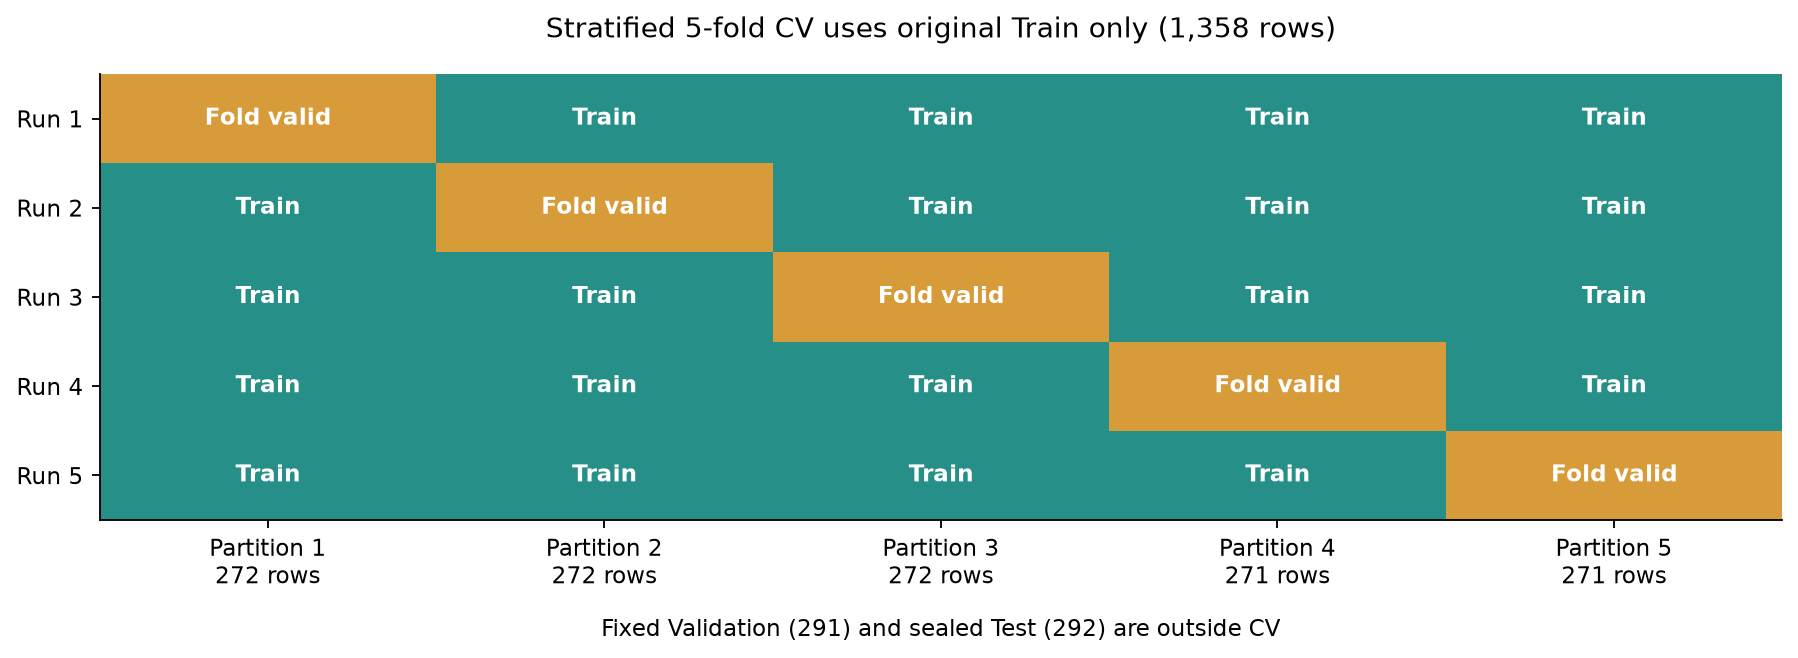

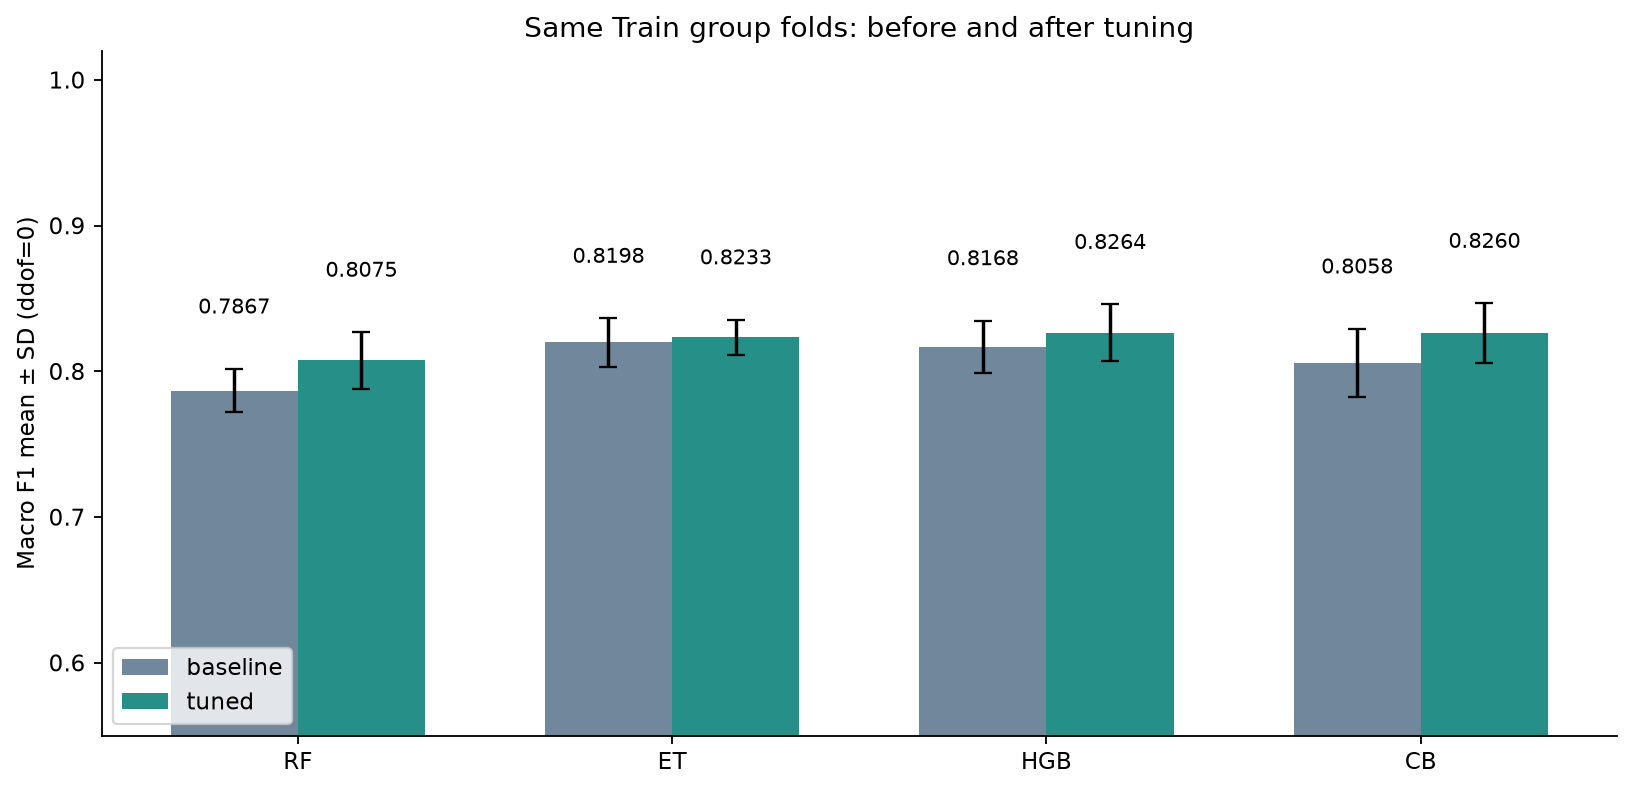

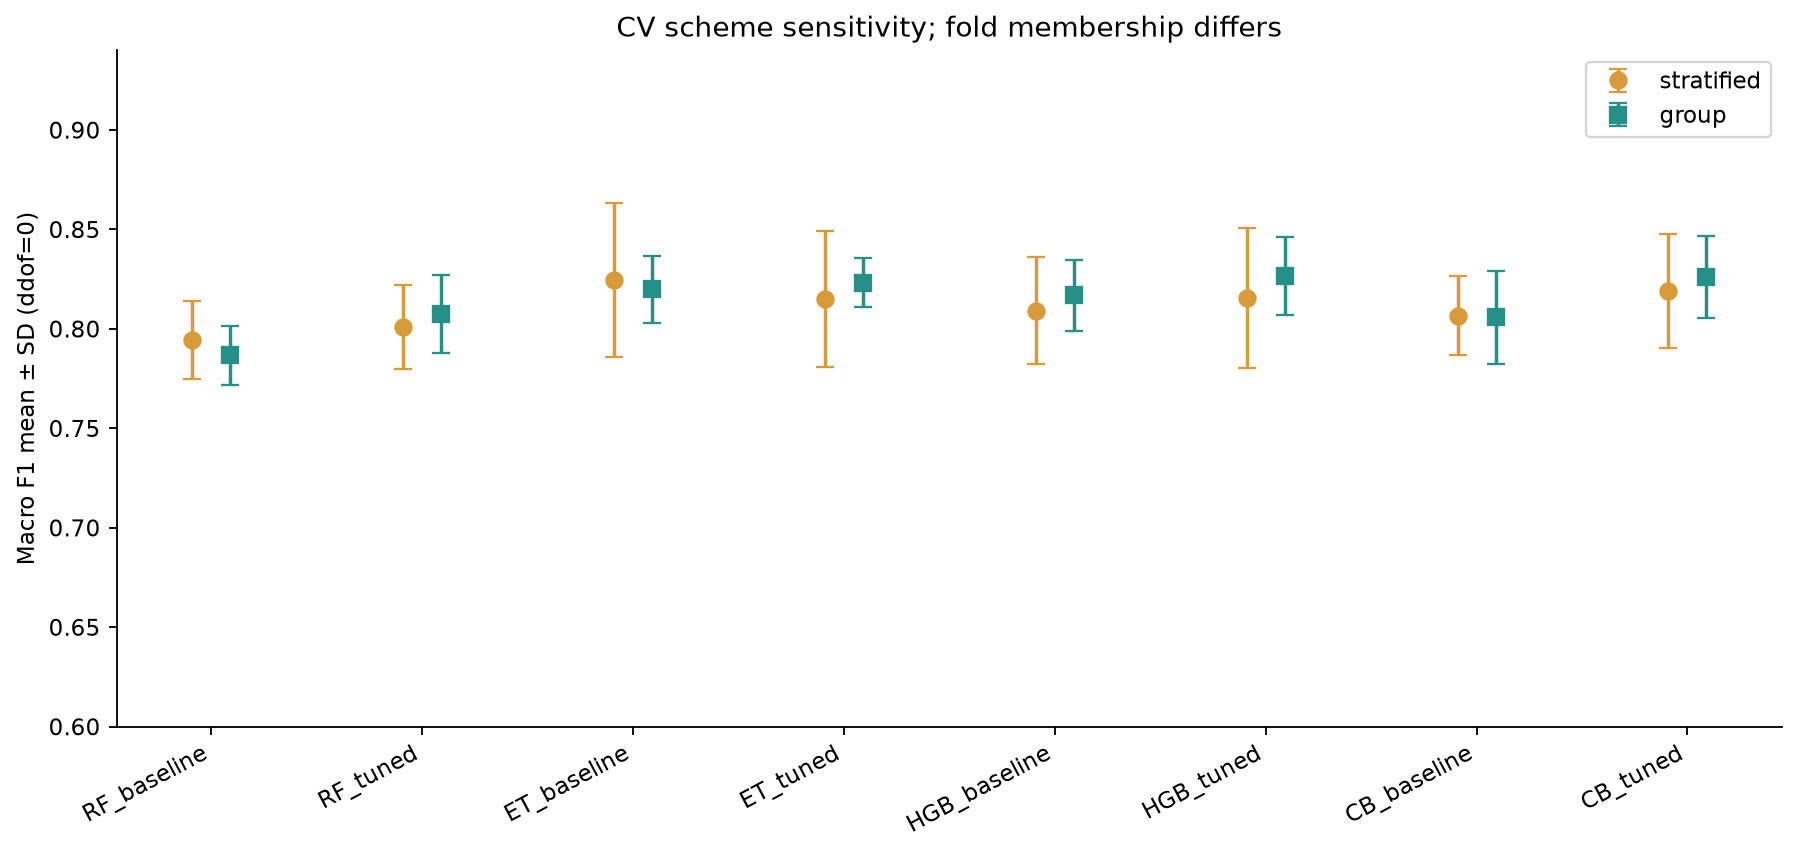

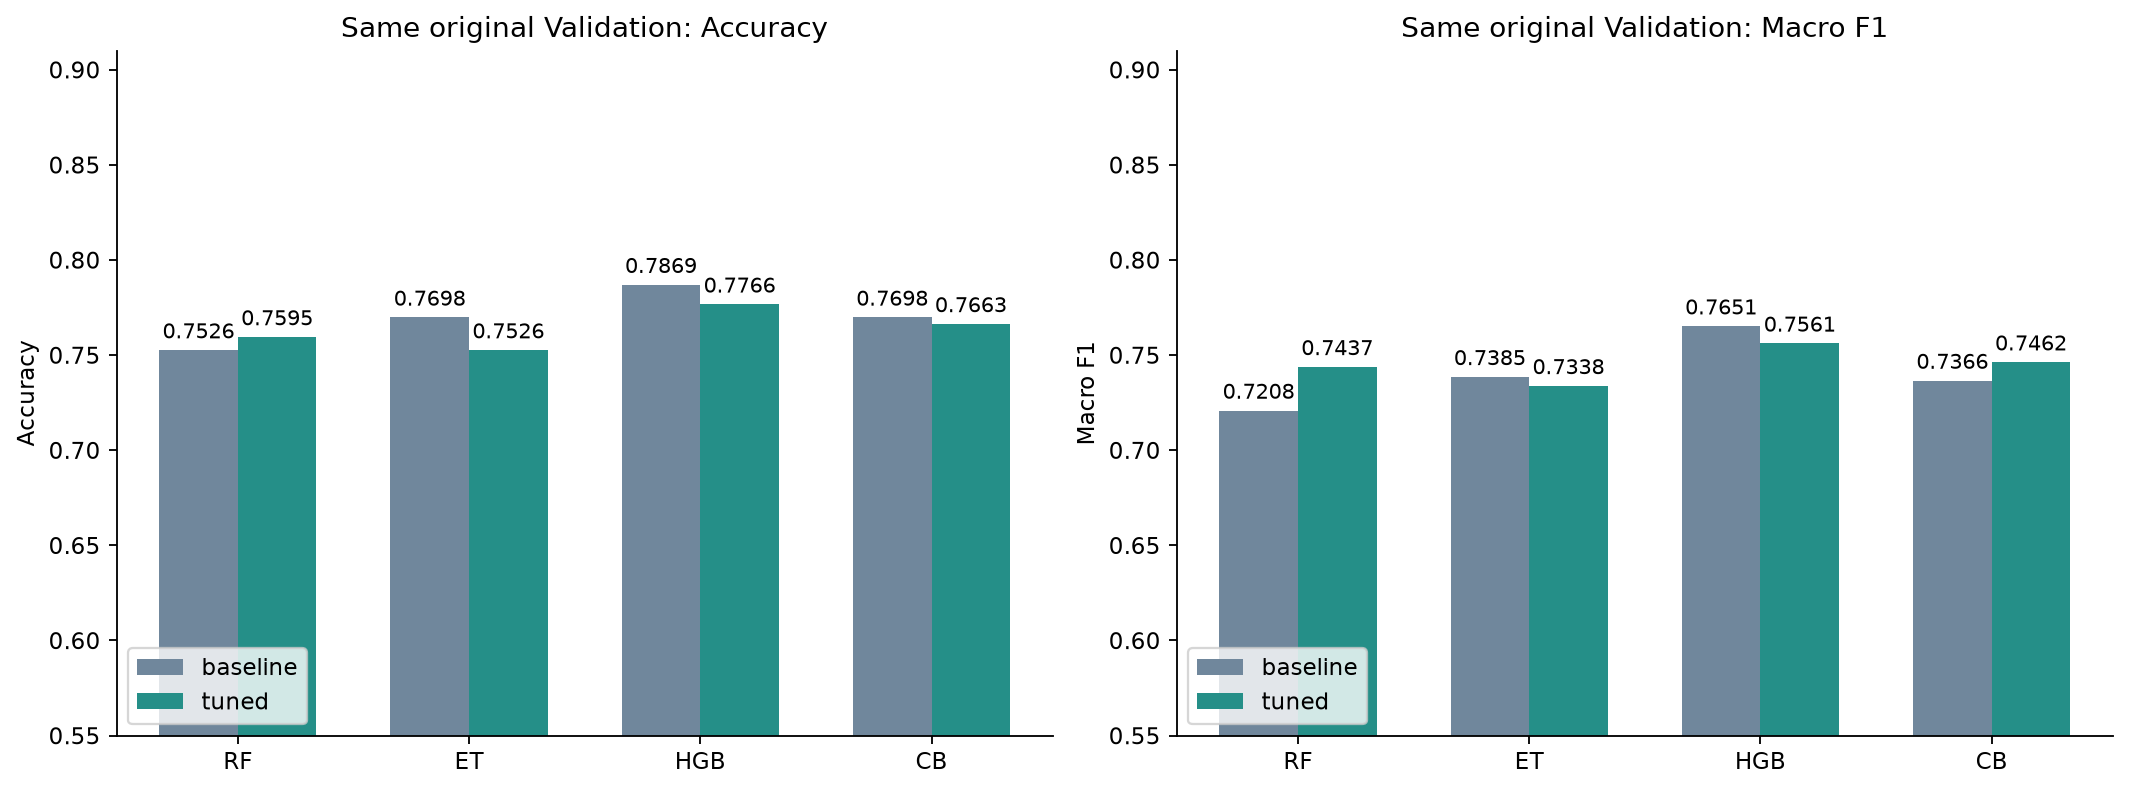

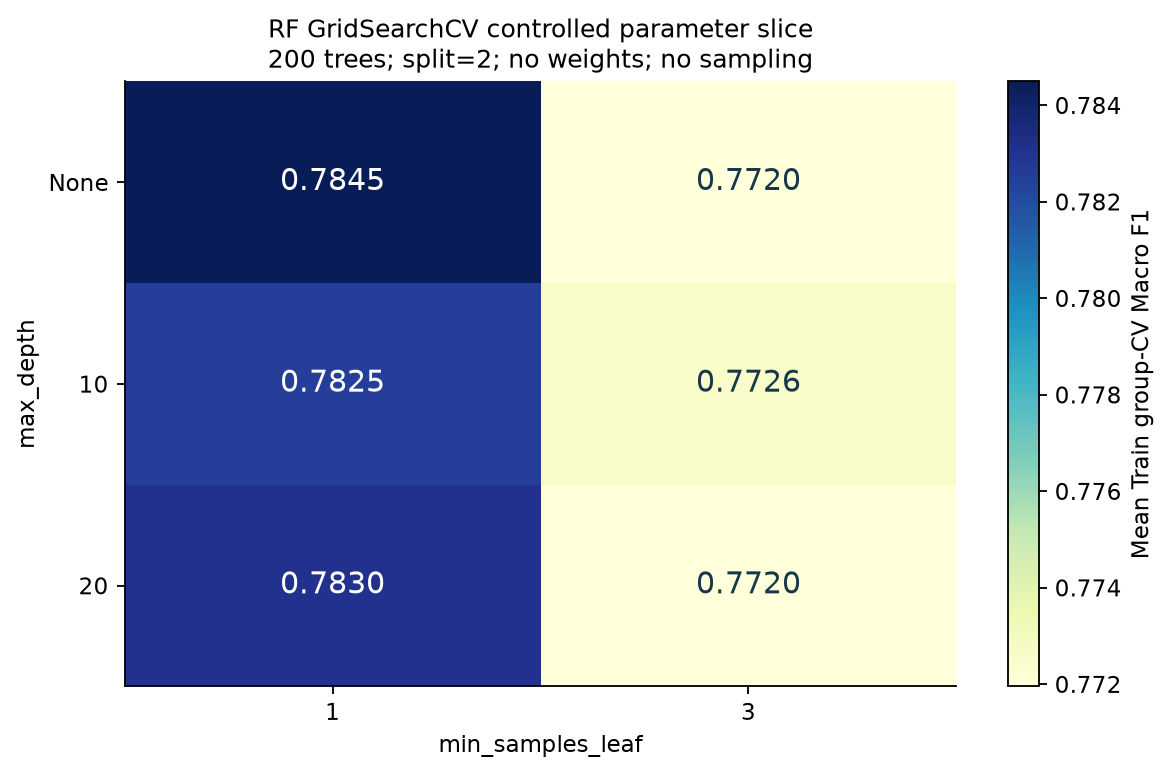

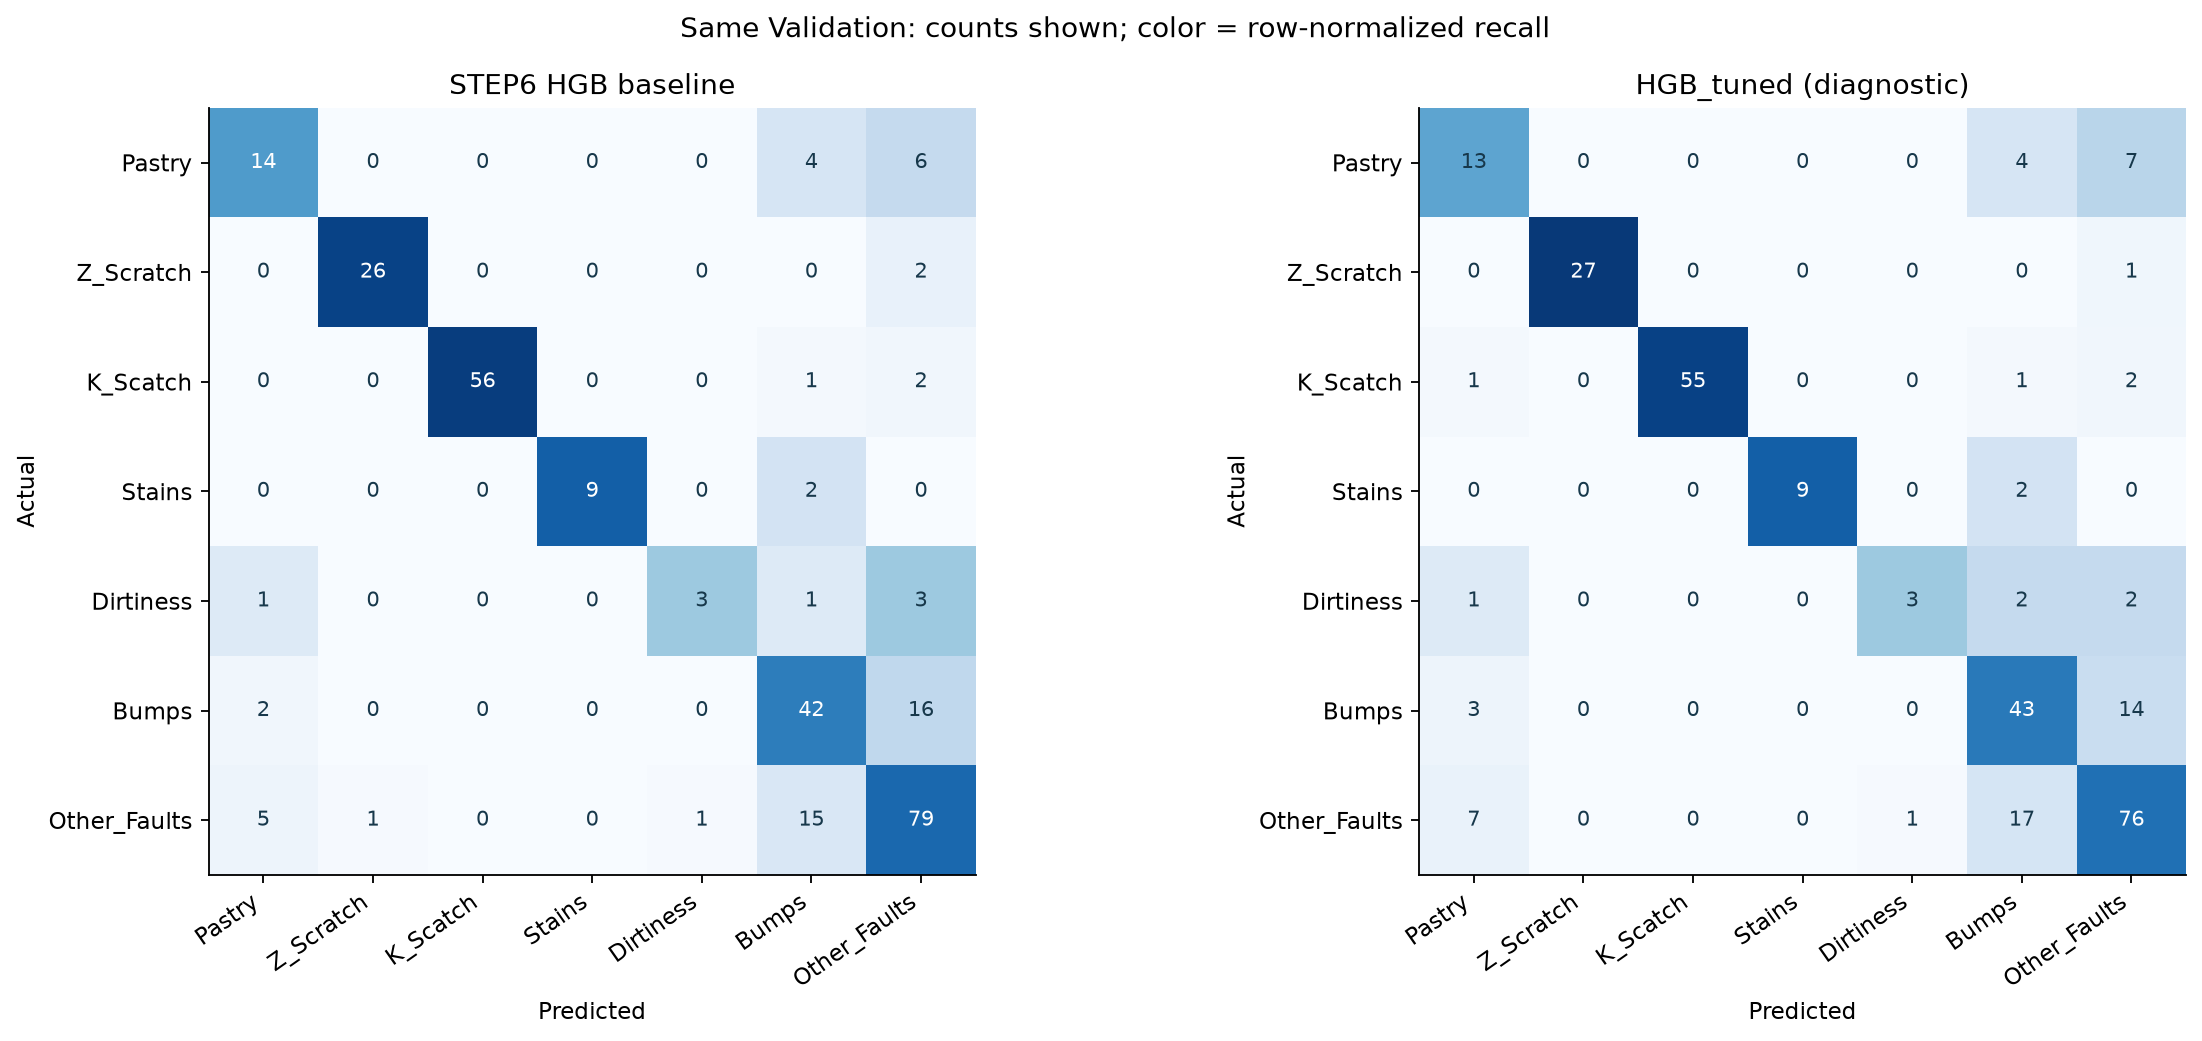

독립 HTML 보고서: STEP7_CV_하이퍼파라미터튜닝_실측보고서.html


,클래스,Valid 건수,기준선 Recall,선정 Recall,Recall 변화,기준선 F1,선정 F1
0,Pastry,24,0.5833,0.5833,0.0,0.6087,0.6087
1,Z_Scratch,28,0.9286,0.9286,0.0,0.9455,0.9455
2,K_Scatch,59,0.9492,0.9492,0.0,0.9739,0.9739
3,Stains,11,0.8182,0.8182,0.0,0.9000,0.9000
4,Dirtiness,8,0.3750,0.3750,0.0,0.5000,0.5000
5,Bumps,60,0.7000,0.7000,0.0,0.6720,0.6720
6,Other_Faults,101,0.7822,0.7822,0.0,0.7560,0.7560


In [13]:
report_path,plots=build_report()
for p in plots:display(Image(filename=str(p)))
print('독립 HTML 보고서:',report_path.name)
display(pd.read_csv(e.OUT/'13_selected_class_comparison.csv').round(4))

## 11. 결과 대조·누수 방지·원본 보존 검증

124개 설정의 Fold 평균·SD를 다시 계산하고, 620개 Grid 평가의 적합 건수·행 분리·Sampling 호출을 확인합니다. 80개 비교 Fold와 저장 OOF 예측, 8개 Valid 모델과 저장 예측, 선정 모델 해시를 대조합니다.

Valid 행으로 fit을 시도하면 실제 학습 전에 차단되는지도 음성 검사합니다. Test를 평가하는 검사는 하지 않습니다.

In [15]:
%pip install "nbformat==5.11.1"


   ----------- ---------------------------- 2/7 [attrs]
   ----------------- ---------------------- 3/7 [referencing]
   ---------------------------- ----------- 5/7 [jsonschema]
   ---------------------------- ----------- 5/7 [jsonschema]
   ---------------------------------- ----- 6/7 [nbformat]
   ---------------------------------- ----- 6/7 [nbformat]
   ---------------------------------------- 7/7 [nbformat]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import nbformat

print(nbformat.__version__)

5.11.1


In [17]:
import check_step7
verified=check_step7.check()
e.dump(e.OUT/'verification_result.json',verified)
display(pd.Series(verified,name='검증 결과').to_frame())
manifest=e.read_json(e.OUT/'execution_manifest.json')
assert manifest['new_test_predictions']==manifest['fitted_test_rows']==manifest['fitted_valid_rows']==0
assert manifest['total_grid_candidates']==124
assert manifest['all_best_group_cv_replay_scores_identical']
print('원본 해시 보존, HGB/RF 기준 예측 일치, 620개 Grid 평가 감사, OOF·Valid 재현 검증 통과')

,검증 결과
grid_configurations_verified,124
grid_cv_fit_audits_verified,620
comparison_oof_fold_metrics_reconciled,80
valid_models_predictions_reconciled,8
original_step4_step6_sources_unchanged,True
non_train_fit_guard_passed,True
selected_model_hash_and_valid_replay_passed,True
selection_reconciled_to_predeclared_gates,True
explicit_utf8_and_windows_posix_paths_passed,True
new_test_predictions,0


원본 해시 보존, HGB/RF 기준 예측 일치, 620개 Grid 평가 감사, OOF·Valid 재현 검증 통과


## 12. 실제 결과 해석·인수인계

튜닝을 수행했다는 사실보다 같은 평가에서 어떤 지표가 바뀌었는지를 봅니다. Macro F1·소수 Recall·Accuracy·학습/CV 차이를 함께 확인하고, 개선이 입증되지 않으면 기준선을 유지할 수 있습니다.

In [ ]:
for line in interpretation(valid,selection):print(line)
print('선정 모델의 학습 건수:',selection['fit_rows'])
print('Test를 튜닝·선정에 사용했는가:',selection['test_used_for_tuning_or_selection'])
print('새 자료 예측: python predict_new.py --input new_features.csv --output predictions.csv')
print('원시 27열만 입력합니다. 정답·행 번호·이미 표준화한 값은 넣지 않습니다.')

RF: 같은 Validation에서 튜닝 전후 Macro F1 0.7208→0.7437 (+0.0229), Accuracy 75.26%→75.95%, 소수 Recall 평균 0.5966→0.5966.
ET: 같은 Validation에서 튜닝 전후 Macro F1 0.7385→0.7338 (-0.0047), Accuracy 76.98%→75.26%, 소수 Recall 평균 0.5966→0.5966.
HGB: 같은 Validation에서 튜닝 전후 Macro F1 0.7651→0.7561 (-0.0090), Accuracy 78.69%→77.66%, 소수 Recall 평균 0.5966→0.5966.
CB: 같은 Validation에서 튜닝 전후 Macro F1 0.7366→0.7462 (+0.0097), Accuracy 76.98%→76.63%, 소수 Recall 평균 0.5966→0.5966.
사전에 정한 개선 조건을 모두 통과한 튜닝 모델이 없어 기존 HGB 기준선을 유지했습니다. 선정 모델 HGB_baseline, Valid Accuracy 78.69%, Macro F1 0.7651입니다.
선정 모델의 학습 건수: 1358
Test를 튜닝·선정에 사용했는가: False
새 자료 예측: python predict_new.py --input new_features.csv --output predictions.csv
원시 27열만 입력합니다. 정답·행 번호·이미 표준화한 값은 넣지 않습니다.


## 해석 범위와 재실행

- Test를 사용하지 않았지만, 기존 Valid/Test가 앞 단계에서 공개된 이력은 없어지지 않습니다. 새로운 최종 성능 검증에는 신규 자료가 필요합니다.
- 이번 CV 최고 점수는 탐색에 사용한 점수라 선택 편향이 있습니다. 추가적인 nested CV를 수행한 결과로 주장하지 않습니다.
- Dirtiness Valid 8건·Stains 11건으로 Recall 1건 차이가 12.5%p·9.09%p입니다. 실제 생산 배치·시간 자료로 다시 검증해야 합니다.
- 전체 패키지에는 코드·실제 GridSearchCV 객체·124개 설정 결과·Fold 지표·OOF·Valid 예측·저장 Pipeline·STEP 4~6 근거가 있습니다.
- 캐시는 프로토콜·코드·원본 서명을 확인하고 재사용합니다. 새 탐색은 프로젝트 복사본과 별도 결과 폴더에서 수행하세요.

공식 구현 근거: [StratifiedKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html), [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html), [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html), [imblearn.Pipeline](https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html).